# Module 3: Exploratory data analysis

EDA of the four cleaned datasets in `data/processed/` (built by `scripts/prepare_data.py`):

1. **Olist** Brazilian e-commerce (`olist.sqlite`)
2. **IPL** ball-by-ball and matches (`ipl_*.csv`)
3. **F1** World Championship, seasons 2014+ (`f1_*.csv`)
4. **Crop production** in India (`crop_production.csv`)

For each: shape, key distributions, trends over time, relationships, and a few charts with a
short takeaway. Data-quality findings are in `docs/data_quality/`. The six charts used in the
report are also saved as PNGs in `docs/eda/`.

In [1]:
import sqlite3
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Works whether the notebook runs from notebooks/ or the repo root.
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data" / "processed"
EDA_DIR = ROOT / "docs" / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)

# Reference palette (validated: categorical slots in fixed order, light mode).
SURFACE, INK, INK_2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
OTHER = "#c3c2b7"  # neutral for an "Other" bucket

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.figsize": (9, 4.6), "figure.dpi": 110, "font.family": "sans-serif", "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK_2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "grid.linestyle": "-",
    "axes.axisbelow": True, "lines.linewidth": 2, "legend.frameon": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
})

def finish(ax, title, subtitle=None, xlabel=None, ylabel=None):
    """Title (left-aligned), optional muted subtitle, axis labels."""
    ax.set_title(title, pad=22 if subtitle else 8)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, color=INK_2, fontsize=9)
    ax.set_xlabel(xlabel or "")
    ax.set_ylabel(ylabel or "")

def end_label(ax, x, y, text, color):
    """Direct label at the end of a line (identity is never color-alone)."""
    ax.annotate(text, (x, y), xytext=(6, 0), textcoords="offset points", va="center",
                color=INK, fontsize=9, fontweight="bold")
    ax.plot([x], [y], "o", color=color, markersize=6, markeredgecolor=SURFACE, markeredgewidth=2)

def save(fig, name):
    """Save a report chart to docs/eda/<name>.png."""
    fig.savefig(EDA_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

BAR = dict(color=BLUE, edgecolor=SURFACE, linewidth=2)  # one series -> one color, 2px gaps

## 1. Olist Brazilian e-commerce

About 99k orders from 2016 to 2018 across 9 linked tables. Prices are in Brazilian reais (R$).

In [2]:
con = sqlite3.connect(f"file:{DATA / 'olist.sqlite'}?mode=ro", uri=True)
tables = [r[0] for r in con.execute("SELECT name FROM sqlite_master WHERE type='table'")]
pd.DataFrame({"table": tables,
              "rows": [con.execute(f'SELECT COUNT(*) FROM "{t}"').fetchone()[0] for t in tables],
              "columns": [len(con.execute(f'PRAGMA table_info("{t}")').fetchall()) for t in tables]})

,table,rows,columns
0,customers,99441,5
1,geolocation,720461,5
2,order_items,112650,7
3,order_payments,103886,5
4,order_reviews,99224,7
5,orders,99441,8
6,products,32951,10
7,sellers,3095,4
8,product_category_name_translation,71,2


In [3]:
orders = pd.read_sql("""
    SELECT o.order_id, o.order_status, o.order_purchase_timestamp AS purchased,
           o.order_delivered_customer_date AS delivered, o.order_estimated_delivery_date AS estimated,
           c.customer_state
    FROM orders o JOIN customers c USING (customer_id)""", con,
    parse_dates=["purchased", "delivered", "estimated"])
reviews = pd.read_sql("SELECT order_id, review_score FROM order_reviews", con).drop_duplicates("order_id")
print("Order status share:", orders.order_status.value_counts(normalize=True).round(3).head(4).to_dict())
print("Review score share:", reviews.review_score.value_counts(normalize=True).sort_index().round(3).to_dict())
orders.groupby(orders.purchased.dt.to_period("M")).size().rename("orders").to_frame().T

Order status share: {'delivered': 0.97, 'shipped': 0.011, 'canceled': 0.006, 'unavailable': 0.006}
Review score share: {1: 0.115, 2: 0.032, 3: 0.082, 4: 0.193, 5: 0.578}


purchased,2016-09,2016-10,2016-12,2017-01,2017-02,2017-03,2017-04,2017-05,2017-06,2017-07,...,2018-01,2018-02,2018-03,2018-04,2018-05,2018-06,2018-07,2018-08,2018-09,2018-10
orders,4,324,1,800,1780,2682,2404,3700,3245,4026,...,7269,6728,7211,6939,6873,6167,6292,6512,16,4


**Coverage note:** 2016 is sparse (November 2016 has no orders at all) and September/October
2018 have only a handful of orders. The trend below uses the complete months, January 2017 to
August 2018.

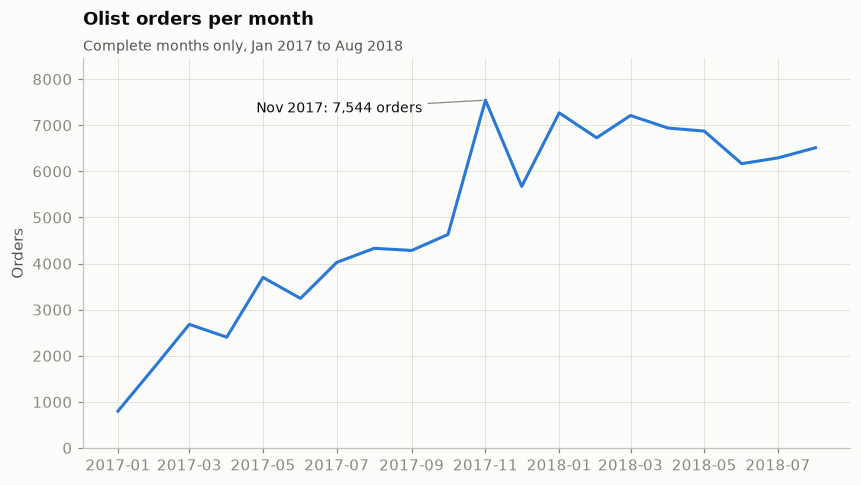

In [4]:
monthly = orders.groupby(orders.purchased.dt.to_period("M")).size()
monthly = monthly["2017-01":"2018-08"]
x = monthly.index.to_timestamp()
fig, ax = plt.subplots()
ax.plot(x, monthly.values, color=BLUE)
peak = monthly.idxmax()
ax.annotate(f"{peak.strftime('%b %Y')}: {monthly.max():,} orders", (peak.to_timestamp(), monthly.max()),
            xytext=(-150, -8), textcoords="offset points", color=INK, fontsize=9,
            arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.set_ylim(0, monthly.max() * 1.12)
finish(ax, "Olist orders per month", "Complete months only, Jan 2017 to Aug 2018", ylabel="Orders")
plt.show()

**Takeaway:** orders grew about 9x in 2017, from 800 in January to a peak of **7,544 in November
2017** (Black Friday month), then plateaued at about 6,200 to 7,300 a month through 2018. Growth,
not seasonality, is the main story; the November spike is the one clear seasonal effect.

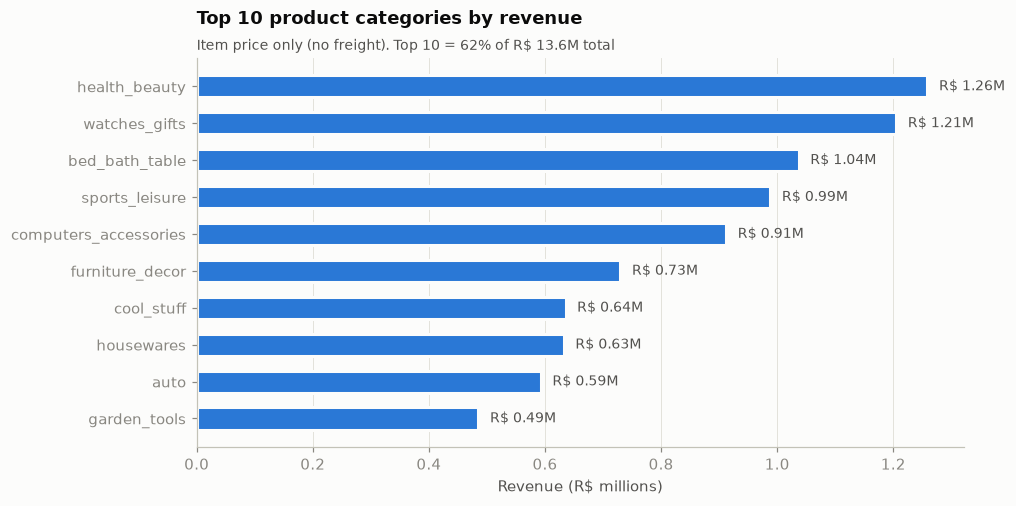

In [5]:
cat = pd.read_sql("""
    SELECT p.product_category_name_english AS category, SUM(i.price) AS revenue, COUNT(*) AS items
    FROM order_items i JOIN products p USING (product_id)
    GROUP BY 1 ORDER BY revenue DESC LIMIT 10""", con)
total = pd.read_sql("SELECT SUM(price) AS s FROM order_items", con).s[0]
fig, ax = plt.subplots()
ax.barh(cat.category[::-1], cat.revenue[::-1] / 1e6, height=0.6, **BAR)
for y, v in enumerate(cat.revenue[::-1] / 1e6):
    ax.text(v + 0.02, y, f"R$ {v:.2f}M", va="center", fontsize=9, color=INK_2)
ax.grid(axis="y", visible=False)
finish(ax, "Top 10 product categories by revenue",
       f"Item price only (no freight). Top 10 = {cat.revenue.sum() / total:.0%} of R$ {total / 1e6:.1f}M total",
       xlabel="Revenue (R$ millions)")
plt.show()

**Takeaway:** revenue is spread out. The top category, health & beauty, earns about R$ 1.26M,
under 10% of the total, and the top 10 together make up about 62%. Bed/bath/table sells the most
items (11.1k) but ranks third on revenue, so it is a lower-price category.

Late deliveries: 6.7% of delivered orders


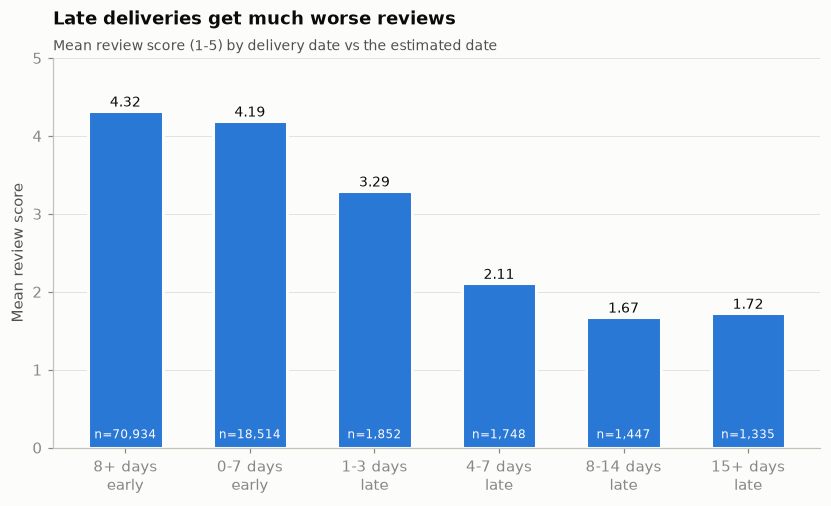

In [6]:
d = orders.merge(reviews, on="order_id")
d = d[d.delivered.notna()].copy()
d["days_vs_estimate"] = (d.delivered.dt.normalize() - d.estimated).dt.days
d["timeliness"] = pd.cut(d.days_vs_estimate, [-999, -8, 0, 3, 7, 14, 999],
                         labels=["8+ days\nearly", "0-7 days\nearly", "1-3 days\nlate",
                                 "4-7 days\nlate", "8-14 days\nlate", "15+ days\nlate"])
by = d.groupby("timeliness", observed=True).review_score.agg(["mean", "size"])
print(f"Late deliveries: {(d.days_vs_estimate > 0).mean():.1%} of delivered orders")
fig, ax = plt.subplots()
bars = ax.bar(by.index.astype(str), by["mean"], width=0.6, **BAR)
for b, (m, n) in zip(bars, by.values):
    ax.text(b.get_x() + b.get_width() / 2, m + 0.06, f"{m:.2f}", ha="center", fontsize=9, color=INK)
    ax.text(b.get_x() + b.get_width() / 2, 0.12, f"n={int(n):,}", ha="center", fontsize=8, color=SURFACE)
ax.set_ylim(0, 5)
ax.grid(axis="x", visible=False)
finish(ax, "Late deliveries get much worse reviews",
       "Mean review score (1-5) by delivery date vs the estimated date", ylabel="Mean review score")
save(fig, "olist_review_vs_delivery")
plt.show()

**Takeaway:** the strongest relationship in Olist. Orders that arrive early average **4.2 to 4.3
stars**; just 1 to 3 days late drops that to **3.3**, and a week or more late to **under 2**. Only
about 7% of delivered orders are late, yet they make up **37% of the 1-star reviews**. Delivery promise
accuracy matters more than raw speed.

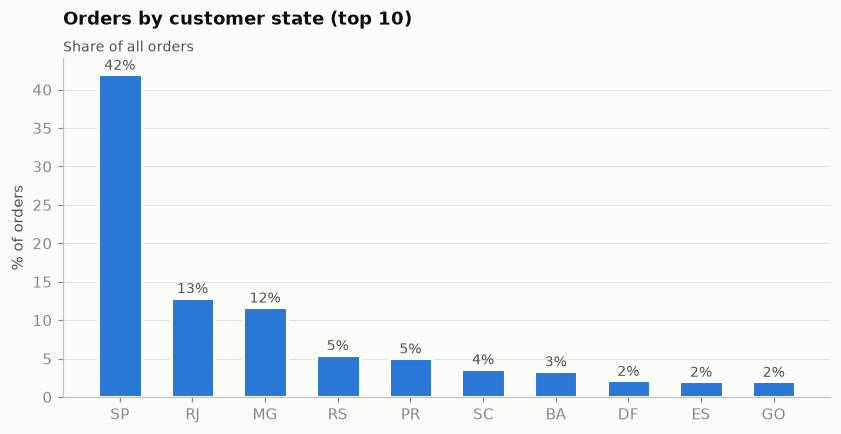

In [7]:
states = orders.customer_state.value_counts().head(10)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(states.index, states.values / len(orders) * 100, width=0.6, **BAR)
for i, v in enumerate(states.values / len(orders) * 100):
    ax.text(i, v + 0.6, f"{v:.0f}%", ha="center", fontsize=9, color=INK_2)
ax.grid(axis="x", visible=False)
finish(ax, "Orders by customer state (top 10)", "Share of all orders", ylabel="% of orders")
plt.show()

**Takeaway:** demand is concentrated in the south-east. São Paulo (SP) alone places **42%** of
orders, and SP, RJ and MG together about 67%. Regional analyses outside the south-east will rest
on small samples.

## 2. IPL (Cricsheet)

Ball-by-ball data for 1,243 men's IPL matches, 2008 to 2026, plus one row per match.

In [8]:
deliv = pd.read_csv(DATA / "ipl_deliveries.csv", low_memory=False)
matches = pd.read_csv(DATA / "ipl_matches.csv", parse_dates=["date"])
print("deliveries:", deliv.shape, "| matches:", matches.shape)
deliv["runs"] = deliv.runs_off_bat + deliv.extras
deliv["legal"] = deliv.wides.isna() & deliv.noballs.isna()
matches.groupby("season").size().rename("matches").to_frame().T

deliveries: (295732, 30) | matches: (1243, 22)


season,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
matches,58,57,60,73,74,76,60,59,60,59,60,60,60,60,74,74,71,74,74


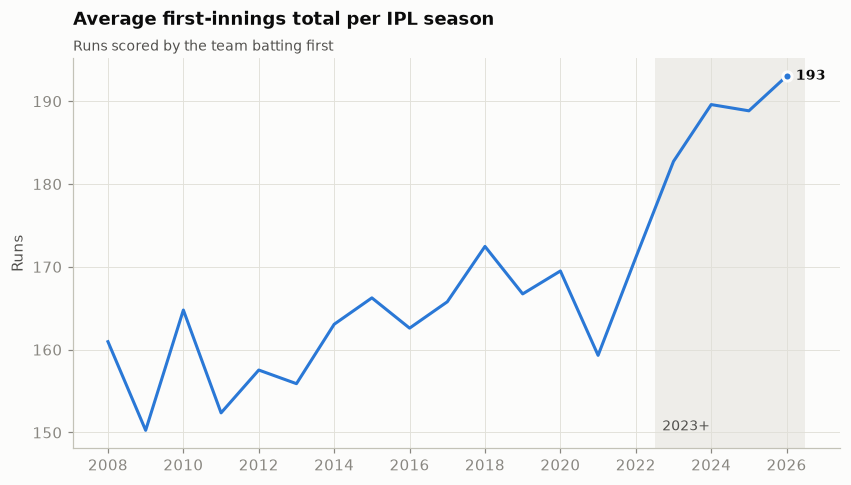

In [9]:
totals = (deliv[deliv.innings == 1].groupby(["season", "match_id"]).runs.sum()
          .groupby("season").mean())
fig, ax = plt.subplots()
ax.plot(totals.index, totals.values, color=BLUE)
ax.axvspan(2022.5, totals.index.max() + 0.5, color=GRID, alpha=0.5, lw=0)
ax.text(2022.7, totals.min(), "2023+", color=INK_2, fontsize=9)
end_label(ax, totals.index[-1], totals.values[-1], f"{totals.values[-1]:.0f}", BLUE)
ax.set_xticks(range(2008, 2027, 2))
finish(ax, "Average first-innings total per IPL season", "Runs scored by the team batting first",
       ylabel="Runs")
save(fig, "ipl_first_innings_totals")
plt.show()

**Takeaway:** scoring sat in a **150 to 173** band for 15 seasons, then jumped: **183 in 2023,
190 in 2024 and 193 in 2026**. The break lines up with the Impact Player rule introduced in 2023.
Sixes per match rose with it (about 12 in 2020 to 19 in 2026), so any "par score" question needs
the season as context.

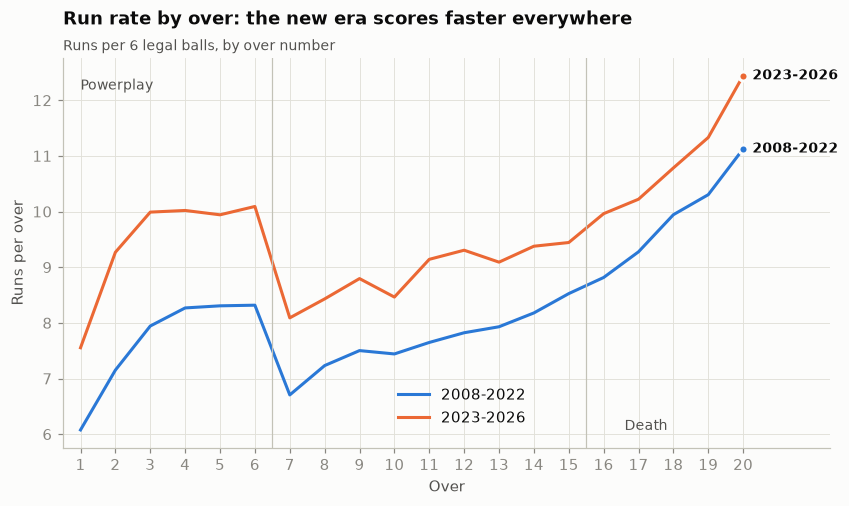

over,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
era,,,,,,,,,,,,,,,,,,,,
2008-2022,6.08,7.15,7.94,8.27,8.31,8.32,6.70,7.23,7.5,7.44,7.65,7.82,7.93,8.18,8.53,8.82,9.28,9.94,10.30,11.13
2023-2026,7.55,9.27,9.99,10.02,9.94,10.09,8.09,8.43,8.8,8.46,9.14,9.31,9.09,9.38,9.44,9.96,10.22,10.78,11.33,12.44


In [10]:
deliv["era"] = np.where(deliv.season >= 2023, "2023-2026", "2008-2022")
rate = (deliv.groupby(["era", "over"]).runs.sum()
        / (deliv[deliv.legal].groupby(["era", "over"]).size() / 6)).unstack(0)
rate.index = rate.index + 1  # overs 1-20
fig, ax = plt.subplots()
for era, color in [("2008-2022", BLUE), ("2023-2026", ORANGE)]:
    ax.plot(rate.index, rate[era], color=color, label=era)
    end_label(ax, 20, rate[era].iloc[-1], era, color)
ax.axvline(6.5, color=AXIS, lw=0.8)
ax.text(1, rate.values.max() * 0.98, "Powerplay", color=INK_2, fontsize=9)
ax.text(16.6, rate.values.min(), "Death", color=INK_2, fontsize=9)
ax.axvline(15.5, color=AXIS, lw=0.8)
ax.set_xticks(range(1, 21))
ax.set_xlim(0.5, 22.5)
ax.legend(loc="lower center", bbox_to_anchor=(0.52, 0.02))
finish(ax, "Run rate by over: the new era scores faster everywhere",
       "Runs per 6 legal balls, by over number", xlabel="Over", ylabel="Runs per over")
save(fig, "ipl_run_rate_by_over")
plt.show()
rate.round(2).T

**Takeaway:** both eras share the same shape: a fast powerplay, a dip in overs 7 to 9, then a
climb to the death overs (over 20 is the fastest). Since 2023 the **powerplay run rate is up
from 7.7 to 9.5** and the middle overs from 7.7 to 8.9, a bigger change than at the death (9.8 to
10.9). Teams now attack from ball one.

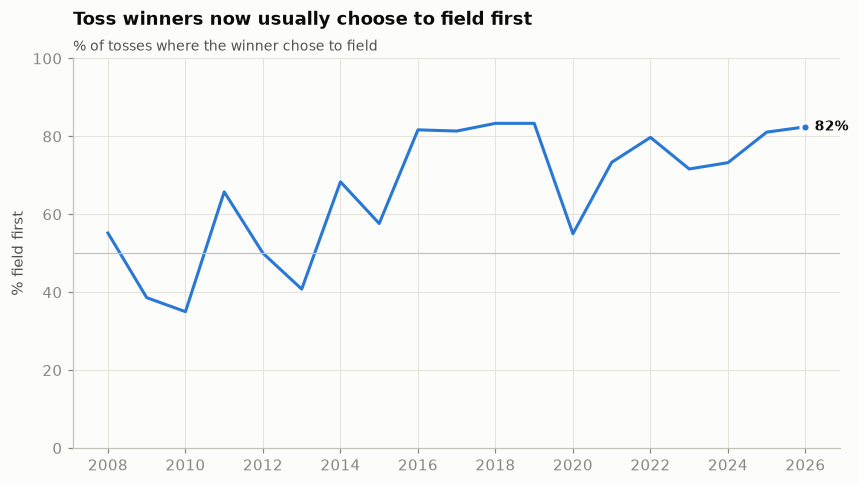

Toss winner went on to win: 51.6% of 1,218 decided matches
Chasing side won: 54.2%


In [11]:
toss = matches.groupby("season").toss_decision.apply(lambda s: (s == "field").mean() * 100)
decided = matches[matches.winner.notna()]
toss_win_rate = (decided.toss_winner == decided.winner).mean()
chase_rate = decided.winner_wickets.notna().mean()
fig, ax = plt.subplots()
ax.plot(toss.index, toss.values, color=BLUE)
ax.axhline(50, color=AXIS, lw=0.8)
end_label(ax, toss.index[-1], toss.values[-1], f"{toss.values[-1]:.0f}%", BLUE)
ax.set_ylim(0, 100)
ax.set_xticks(range(2008, 2027, 2))
finish(ax, "Toss winners now usually choose to field first",
       "% of tosses where the winner chose to field", ylabel="% field first")
plt.show()
print(f"Toss winner went on to win: {toss_win_rate:.1%} of {len(decided):,} decided matches")
print(f"Chasing side won: {chase_rate:.1%}")

**Takeaway:** fielding first went from the minority choice (35 to 39% in 2009 and 2010) to the
default (**72 to 83% every season since 2016**, except 55% in 2020). Yet winning the toss barely helps:
the toss winner won **51.6%** of decided matches, and chasing sides won about 54%. The
preference is stronger than the edge it buys.

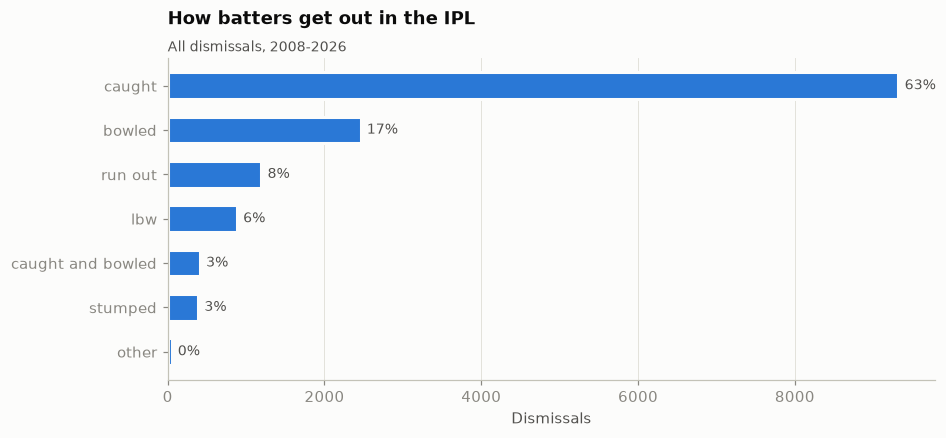

In [12]:
dismissals = deliv.wicket_type.value_counts()
top = dismissals.head(6)
top["other"] = dismissals.iloc[6:].sum()
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.barh(top.index[::-1], top.values[::-1], height=0.6, **BAR)
for y, v in enumerate(top.values[::-1]):
    ax.text(v + 80, y, f"{v / dismissals.sum():.0%}", va="center", fontsize=9, color=INK_2)
ax.grid(axis="y", visible=False)
finish(ax, "How batters get out in the IPL", "All dismissals, 2008-2026", xlabel="Dismissals")
plt.show()

**Takeaway:** **63% of dismissals are catches** (plus 3% caught-and-bowled). Bowled (17%), run out
(8%) and lbw (6%) follow. In T20 cricket, wickets mostly come from batters taking risks in the
air, consistent with the rising six count.

## 3. Formula 1 (Jolpica-F1), seasons 2014 to 2026

The hybrid-engine era. **2026 is in progress**: the dump runs to late October 2026.

In [13]:
races = pd.read_csv(DATA / "f1_races.csv", parse_dates=["date"])
results = pd.read_csv(DATA / "f1_session_results.csv")
pits = pd.read_csv(DATA / "f1_pit_stops.csv")
race = results[results.session_type == "R"].copy()
for name, df in [("races", races), ("session_results", results), ("race results", race), ("pit_stops", pits)]:
    print(f"{name:16} {df.shape}")
races.groupby("season").size().rename("races").to_frame().T

races            (276, 9)
session_results  (21456, 19)
race results     (5501, 19)
pit_stops        (10076, 12)


season,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
races,19,19,21,20,21,21,17,22,22,22,24,24,24


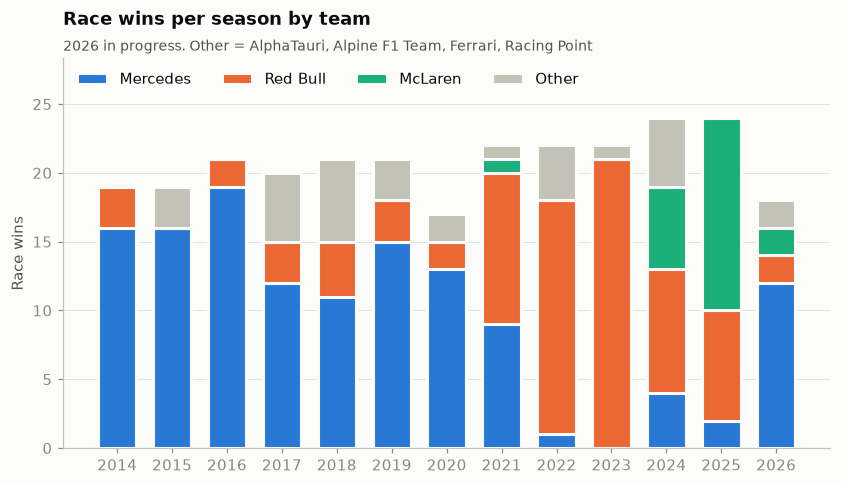

season,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
team_name,,,,,,,,,,,,,
Mercedes,16,16,19,12,11,15,13,9,1,0,4,2,12
Red Bull,3,0,2,3,4,3,2,11,17,21,9,8,2
McLaren,0,0,0,0,0,0,0,1,0,0,6,14,2
Other,0,3,0,5,6,3,2,1,4,1,5,0,2


In [14]:
wins = race[race.position == 1].groupby(["season", "team_name"]).size().unstack(fill_value=0)
main = ["Mercedes", "Red Bull", "McLaren"]
other_teams = [t for t in wins.columns if t not in main and wins[t].sum() > 0]
wins["Other"] = wins.drop(columns=main).sum(axis=1)
wins = wins[main + ["Other"]]
fig, ax = plt.subplots()
bottom = np.zeros(len(wins))
for team, color in zip(wins.columns, [BLUE, ORANGE, AQUA, OTHER]):
    ax.bar(wins.index, wins[team], bottom=bottom, width=0.7, color=color, edgecolor=SURFACE,
           linewidth=2, label=team)
    bottom += wins[team].values
ax.set_xticks(wins.index)
ax.grid(axis="x", visible=False)
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, 1.0))
ax.set_ylim(0, bottom.max() * 1.18)
finish(ax, "Race wins per season by team", f"2026 in progress. Other = {', '.join(other_teams)}",
       ylabel="Race wins")
save(fig, "f1_wins_by_team")
plt.show()
wins.T

**Takeaway:** three eras of dominance. **Mercedes won 102 of 138 races in 2014 to 2020**, Red Bull
took over (17 wins in 2022, **21 of 22 in 2023**), and McLaren led 2025 with 14 wins. Mercedes is
back on top in 2026 (12 wins so far). Season-level questions like "who dominated" depend heavily
on which seasons are included.

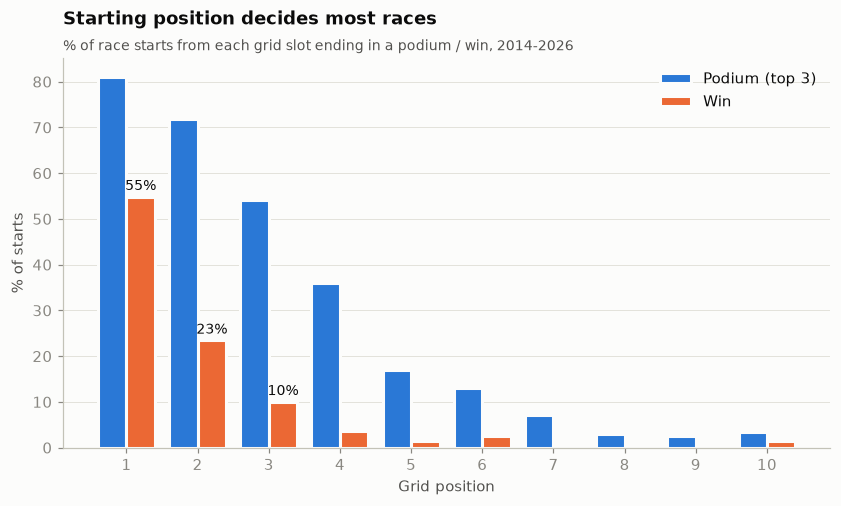

grid,1.0,2.0,3.0,4.0,5.0,6.0,7.0,8.0,9.0,10.0
win,54.8,23.4,10.0,3.7,1.5,2.6,0.4,0.4,0.4,1.5
podium,81.1,71.7,54.1,35.9,17.0,13.0,7.1,3.0,2.6,3.4


In [15]:
g = race[race.grid.between(1, 10)]
by_grid = g.groupby("grid").position.agg(win=lambda s: (s == 1).mean() * 100,
                                         podium=lambda s: (s <= 3).mean() * 100)
x = np.arange(1, 11)
fig, ax = plt.subplots()
ax.bar(x - 0.2, by_grid.podium, width=0.4, color=BLUE, edgecolor=SURFACE, linewidth=2, label="Podium (top 3)")
ax.bar(x + 0.2, by_grid.win, width=0.4, color=ORANGE, edgecolor=SURFACE, linewidth=2, label="Win")
for xi, w in zip(x[:3], by_grid.win[:3]):
    ax.text(xi + 0.2, w + 1.5, f"{w:.0f}%", ha="center", fontsize=9, color=INK)
ax.set_xticks(x)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper right")
finish(ax, "Starting position decides most races", "% of race starts from each grid slot ending in a podium / win, 2014-2026",
       xlabel="Grid position", ylabel="% of starts")
save(fig, "f1_grid_vs_result")
plt.show()
by_grid.round(1).T

**Takeaway:** pole position converts to a win **55%** of the time and to a podium 81% of the time.
The win rate halves with each slot (P2 23%, P3 10%) and is near zero from P5 back. Qualifying is
the single best predictor of a race result in this era.

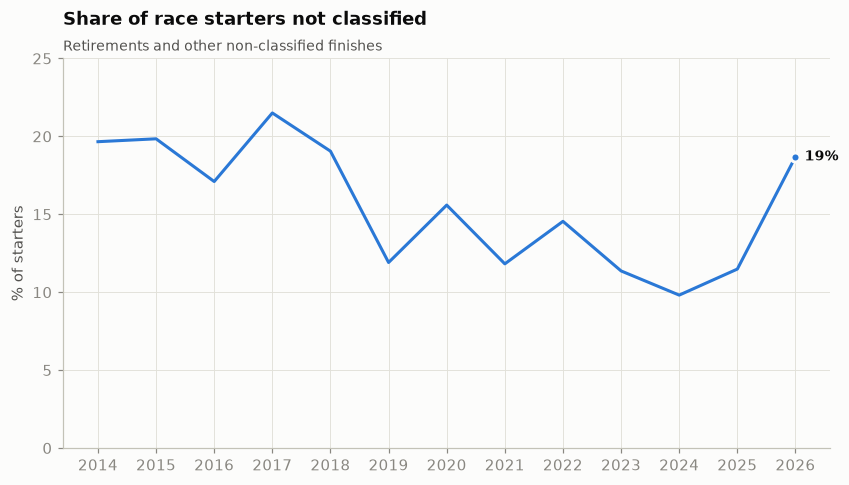

Most common reasons: {'Retired': 228, 'Collision': 120, 'Accident': 66, 'Engine': 62, 'Collision damage': 40}


In [16]:
dnf = race.groupby("season").is_classified.apply(lambda s: (~s.astype(bool)).mean() * 100)
fig, ax = plt.subplots()
ax.plot(dnf.index, dnf.values, color=BLUE)
end_label(ax, dnf.index[-1], dnf.values[-1], f"{dnf.values[-1]:.0f}%", BLUE)
ax.set_ylim(0, 25)
ax.set_xticks(dnf.index)
finish(ax, "Share of race starters not classified", "Retirements and other non-classified finishes",
       ylabel="% of starters")
plt.show()
print("Most common reasons:", race[~race.is_classified.astype(bool)].detail.value_counts().head(5).to_dict())

**Takeaway:** reliability improved: about **20% of starters were not classified in 2014 to 2018**,
falling to **10 to 12% in 2023 to 2025**. 2026 (in progress) is back up near 19%; this data does
not say why. Collisions and accidents are
the most common recorded reasons after the generic "Retired".

Longest recorded stop: 3,069 s (likely a red-flag stoppage), so medians below


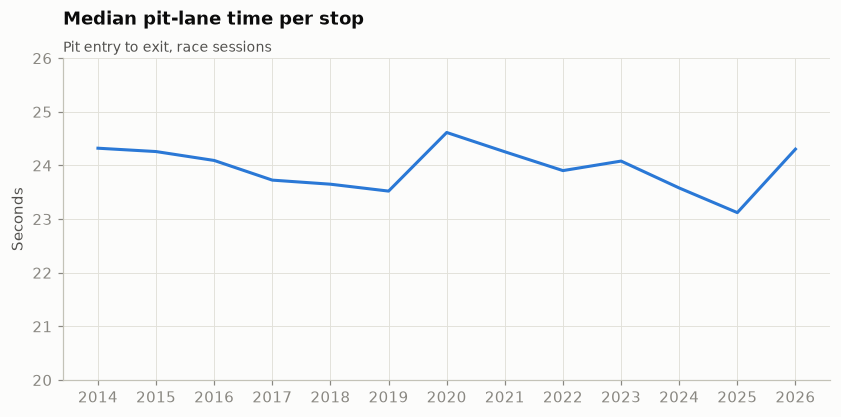

In [17]:
race_pits = pits[(pits.session_type == "R") & pits.duration_ms.notna()]
median_pit = race_pits.groupby("season").duration_ms.median() / 1000
print(f"Longest recorded stop: {race_pits.duration_ms.max() / 1000:,.0f} s (likely a red-flag stoppage), so medians below")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(median_pit.index, median_pit.values, color=BLUE)
ax.set_ylim(20, 26)
ax.set_xticks(median_pit.index)
finish(ax, "Median pit-lane time per stop", "Pit entry to exit, race sessions", ylabel="Seconds")
plt.show()

**Takeaway:** the recorded duration is **pit-lane time (median about 23 to 24.5 s)**, entry to
exit, not the few seconds the car is stationary, so it barely moves year to year. A few stops last
thousands of seconds (likely red-flag periods), which would wreck averages: use medians, or filter
outliers, for any pit-stop question.

## 4. Crop production in India (data.gov.in via Kaggle mirror)

District-level area and production by crop, season and year.

In [18]:
crop = pd.read_csv(DATA / "crop_production.csv")
print(crop.shape)
print("rows per year:", crop.groupby("crop_year").size().to_dict())
print("states:", crop.state_name.nunique(), "| districts:", crop.district_name.nunique(),
      "| crops:", crop.crop.nunique())
crop.groupby("crop").production.sum().sort_values(ascending=False).head(5)

(246091, 7)
rows per year: {1997: 8899, 1998: 11533, 1999: 12515, 2000: 13658, 2001: 13361, 2002: 16671, 2003: 17287, 2004: 14117, 2005: 13799, 2006: 14328, 2007: 14526, 2008: 14550, 2009: 14116, 2010: 14065, 2011: 14071, 2012: 13410, 2013: 13650, 2014: 10973, 2015: 562}
states: 33 | districts: 646 | crops: 124


crop
Coconut      1.299816e+11
Sugarcane    5.535682e+09
Rice         1.605470e+09
Wheat        1.332826e+09
Potato       4.248263e+08
Name: production, dtype: float64

**Units warning:** coconut "production" (about 130 billion) dwarfs every other crop because it is
counted in nuts, not tonnes. Totals across crops are not meaningful, so the charts below look at
one crop at a time or at area (hectares). **2014 is incomplete for wheat and 2015 has only 562
rows**, so trends stop at 2013.

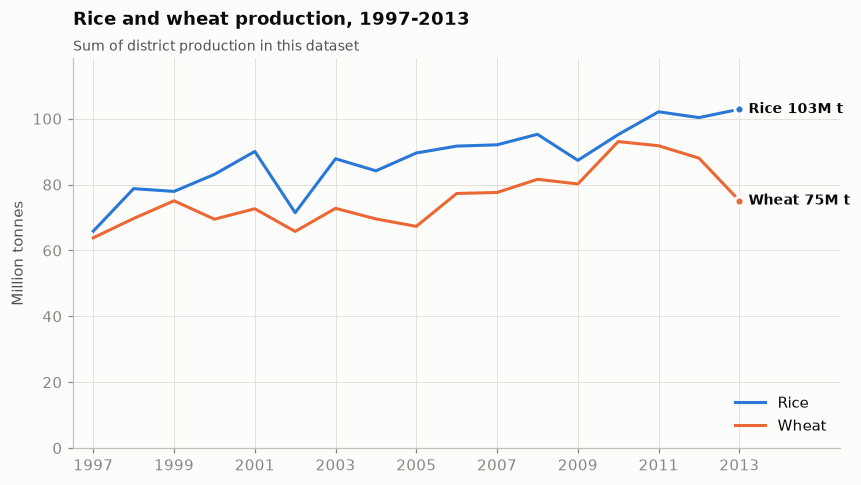

crop_year,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013
crop,,,,,,,,,,,,,,,,,
Rice,65.8,78.8,77.9,83.1,90.1,71.5,87.8,84.2,89.6,91.7,92.1,95.3,87.4,95.2,102.1,100.3,102.9
Wheat,63.8,69.7,75.1,69.5,72.6,65.8,72.8,69.6,67.3,77.3,77.6,81.6,80.2,93.0,91.8,88.0,75.1


In [19]:
trend = (crop[crop.crop.isin(["Rice", "Wheat"]) & crop.crop_year.between(1997, 2013)]
         .groupby(["crop_year", "crop"]).production.sum().unstack() / 1e6)
fig, ax = plt.subplots()
for c, color in [("Rice", BLUE), ("Wheat", ORANGE)]:
    ax.plot(trend.index, trend[c], color=color, label=c)
    end_label(ax, trend.index[-1], trend[c].iloc[-1], f"{c} {trend[c].iloc[-1]:.0f}M t", color)
ax.set_ylim(0, trend.values.max() * 1.15)
ax.set_xlim(1996.5, 2015.5)
ax.set_xticks(range(1997, 2014, 2))
ax.legend(loc="lower right")
finish(ax, "Rice and wheat production, 1997-2013", "Sum of district production in this dataset",
       ylabel="Million tonnes")
save(fig, "crop_rice_wheat_trend")
plt.show()
trend.round(1).T

**Takeaway:** rice rose from **66M t (1997) to 103M t (2013)** and wheat from 64M t to a peak of
93M t in 2010. Both dip in **2002**, the year of a major monsoon drought. Early years have fewer
reporting districts (8.9k rows in 1997 vs 13 to 17k later), so part of the 1997 to 2001 growth is
coverage, not output.

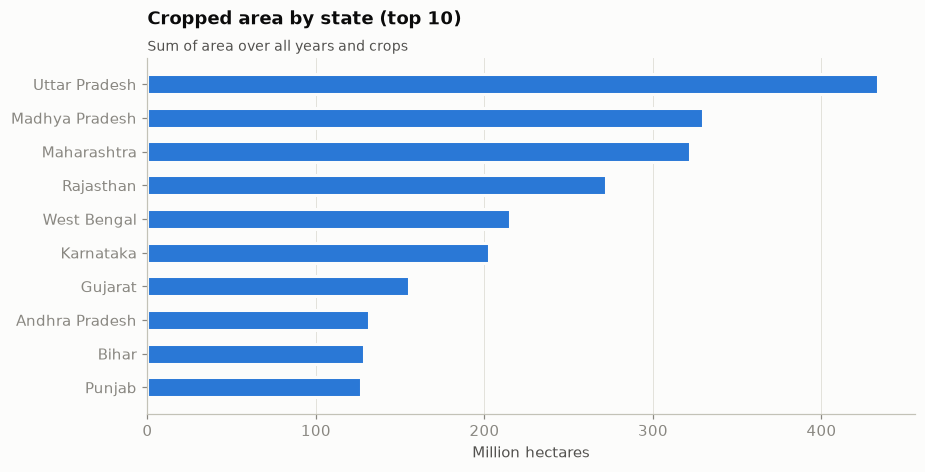

season
Kharif        47.6
Rabi          32.1
Whole Year     8.7
Winter         7.4
Summer         2.6
Autumn         1.6
Name: area, dtype: float64

In [20]:
area_state = crop.groupby("state_name").area.sum().sort_values(ascending=False).head(10) / 1e6
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.barh(area_state.index[::-1], area_state.values[::-1], height=0.6, **BAR)
ax.grid(axis="y", visible=False)
finish(ax, "Cropped area by state (top 10)", "Sum of area over all years and crops", xlabel="Million hectares")
plt.show()
season_share = (crop.groupby("season").area.sum() / crop.area.sum() * 100).sort_values(ascending=False)
season_share.round(1)

**Takeaway:** **Uttar Pradesh** has the most cropped area by a wide margin, followed by Madhya
Pradesh, Maharashtra and Rajasthan. By season, **Kharif (monsoon) covers about 48%** of the area
and Rabi (winter) about 32%, so the monsoon season drives most of India's farm output.

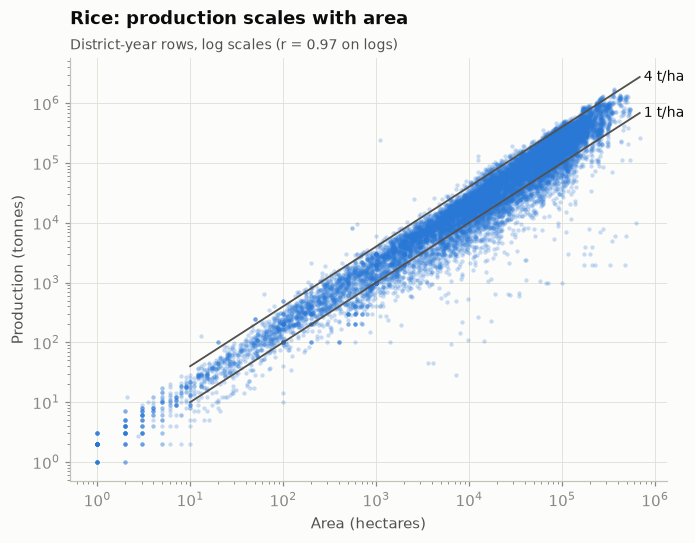

state_name
Chandigarh        4.53
Punjab            3.73
Tamil Nadu        3.09
Andhra Pradesh    3.04
Telangana         2.88
dtype: float64

In [21]:
rice = crop[(crop.crop == "Rice") & (crop.area > 0) & (crop.production > 0) & (crop.crop_year <= 2013)]
corr = np.corrcoef(np.log10(rice.area), np.log10(rice.production))[0, 1]
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(rice.area, rice.production, s=8, color=BLUE, alpha=0.25, linewidths=0)
for y_t_ha, label in [(1, "1 t/ha"), (4, "4 t/ha")]:
    xs = np.array([10, rice.area.max()])
    ax.plot(xs, xs * y_t_ha, color=INK_2, lw=1.2, zorder=3)
    ax.text(xs[1], xs[1] * y_t_ha, f" {label}", color=INK, fontsize=9, va="center", zorder=4)
ax.set_xscale("log"); ax.set_yscale("log")
finish(ax, "Rice: production scales with area", f"District-year rows, log scales (r = {corr:.2f} on logs)",
       xlabel="Area (hectares)", ylabel="Production (tonnes)")
plt.show()
yield_state = (rice.groupby("state_name").apply(lambda d: d.production.sum() / d.area.sum(), include_groups=False)
               .sort_values(ascending=False))
yield_state.head(5).round(2)

**Takeaway:** area explains most of production (**r = 0.97** on log scales), and most
district-years fall between **1 and 4 tonnes per hectare**. The spread between those lines is
yield: Punjab averages about 3.7 t/ha against 1.3 to 1.6 t/ha in Bihar, Odisha, Assam and Chhattisgarh, so yield,
not just area, is worth modelling.

## Summary

| Dataset | Strongest pattern | Caveat for analysis |
|---|---|---|
| Olist | Late delivery drops reviews from about 4.3 to under 2 stars | 2016 and Sep/Oct 2018 are partial |
| IPL | Scoring jumped about 20 runs per innings from 2023 | Compare seasons within an era |
| F1 | Pole wins 55% of races; team eras dominate | 2026 in progress; pit time = pit-lane time |
| Crop | Rice output +56% from 1997 to 2013; area drives production | Mixed units (coconut); 2014-15 incomplete |

Report charts saved to `docs/eda/`.